# **Part 1 — Dataset**

## Overview

A convolutional neural network (CNN) that classifies tomato leaf images into **6 classes** (5 diseases + healthy), together with a study of whether an image-enhancement **preprocessing** step improves the results.

Dataset: [Tomato Leaf Disease Dataset (6 classes)](https://www.kaggle.com/datasets/syedhashirali260/tomato-leaf-disease-dataset-6-classes) by syedhashirali260, 1,200 images per class (7,200 in total).

## Pipeline

Images → LAB conversion → Bilateral filter (L channel) → CLAHE (L channel) → Resize 128×128 → CNN → Evaluation
↕ comparison with the original images (no preprocessing) → same CNN → Evaluation

1. **Dataset exploration**: classes, image counts and sample images
2. **Preprocessing**: BGR → LAB, bilateral filter and CLAHE on the L channel; quality measured with SSIM and PSNR
3. **Training**: stratified 70 / 20 / 10 train / validation / test split, custom CNN (3 Conv blocks with BatchNorm, MaxPooling and Dropout, then a Dense head), Adam optimizer, EarlyStopping and ReduceLROnPlateau callbacks
4. **Evaluation**: classification report and confusion matrix on the test set
5. **Comparison**: the same model, hyperparameters and seed trained on the original images, compared on the same test set

## Findings

With preprocessing, the model reaches **[XX]% test accuracy** (macro F1 [0.XX]); without preprocessing, **[XX]%** (macro F1 [0.XX]). [One sentence: whether preprocessing helped, and by how much. Example: "The difference is within what random variation can explain, so preprocessing gives no clear gain on this dataset."] The weakest classes are [class names].

Course project, Univesity of Science and technology Mohamed Boudiaf of ORAN (Master AI & Applications, 2025/2026).

Classes and number of images:
  Tomato_Early_blight: 1200 images
  Tomato_Healthy: 1200 images
  Tomato_leaf_late_blight: 1200 images
  Tomato_leaf_yellow_curl_virus: 1200 images
  Tomato_mold_leaf: 1200 images
  Tomato_septora_leaf_spot: 1200 images


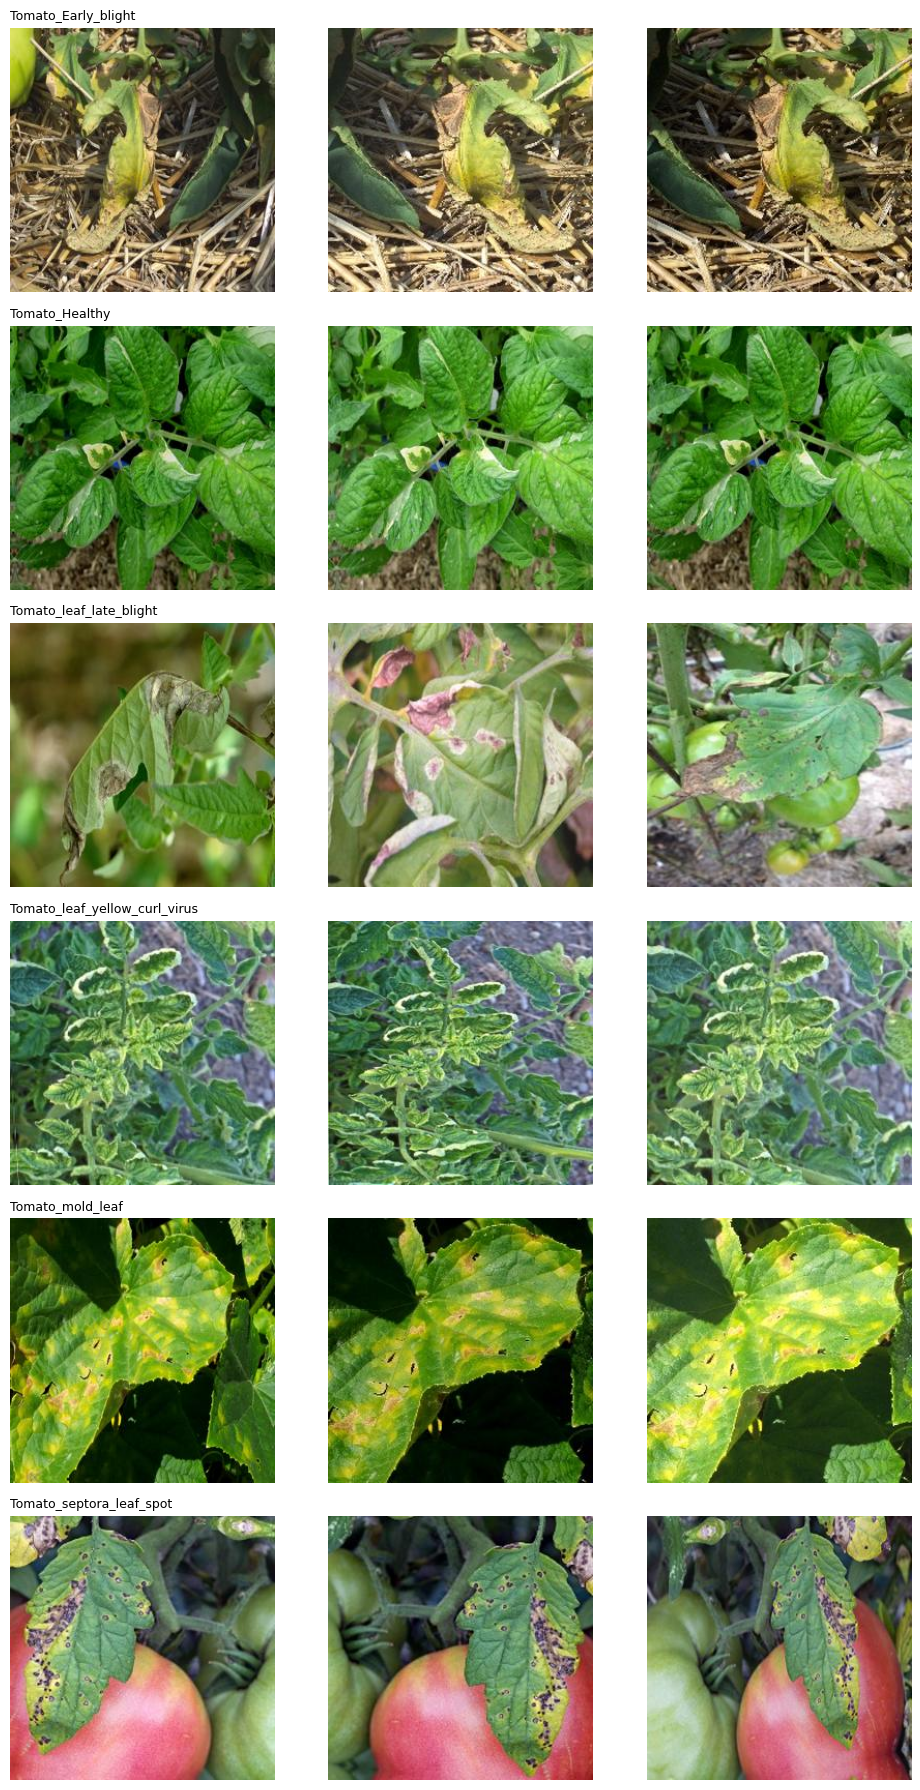

In [1]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Kaggle paths first, local fallbacks otherwise
KAGGLE_DATA = "/kaggle/input/datasets/syedhashirali260/tomato-leaf-disease-dataset-6-classes/Tomato_Leaf_Dataset"
data_dir = KAGGLE_DATA if os.path.isdir(KAGGLE_DATA) else "Tomato_Leaf_Dataset"
OUTPUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def get_images(cls_path):
    return [f for f in os.listdir(cls_path)
            if os.path.isfile(os.path.join(cls_path, f)) and f.lower().endswith(('.jpg', '.jpeg', '.png'))]

classes = sorted(os.listdir(data_dir))
class_counts = {cls: len(get_images(os.path.join(data_dir, cls))) for cls in classes}

print("Classes and number of images:")
for cls, count in class_counts.items():
    print(f"  {cls}: {count} images")

fig, axes = plt.subplots(len(classes), 3, figsize=(10, 3 * len(classes)))
for i, cls in enumerate(classes):
    cls_path = os.path.join(data_dir, cls)
    images = get_images(cls_path)[:3]
    for j, img_name in enumerate(images):
        img = cv2.cvtColor(cv2.imread(os.path.join(cls_path, img_name)), cv2.COLOR_BGR2RGB)
        axes[i][j].imshow(img)
        axes[i][j].axis('off')
        if j == 0:
            axes[i][j].set_title(cls, fontsize=9, loc='left')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "part1_classes.png"), dpi=100)
plt.show()

# **Part 2 — Preprocessing**

Preprocessing pipeline applied to each image:
1. **BGR → LAB** conversion to separate luminance (L channel) from chrominance
2. **Bilateral filter** on the L channel: smooths noise while preserving edges
3. **CLAHE** (Contrast Limited Adaptive Histogram Equalization) on the filtered L channel: local contrast enhancement

Preprocessing quality is evaluated per class (on one example image per class) with:
- **SSIM** (Structural Similarity Index): measures structural fidelity (close to 1 = good)
- **PSNR** (Peak Signal-to-Noise Ratio): measures the level of distortion (higher = better)

Class                                 SSIM   PSNR (dB)
-------------------------------------------------------
Tomato_Early_blight                 0.7678       19.29
Tomato_Healthy                      0.6133       18.07
Tomato_leaf_late_blight             0.7440       20.92
Tomato_leaf_yellow_curl_virus       0.7326       20.59
Tomato_mold_leaf                    0.6189       20.21
Tomato_septora_leaf_spot            0.7479       20.24


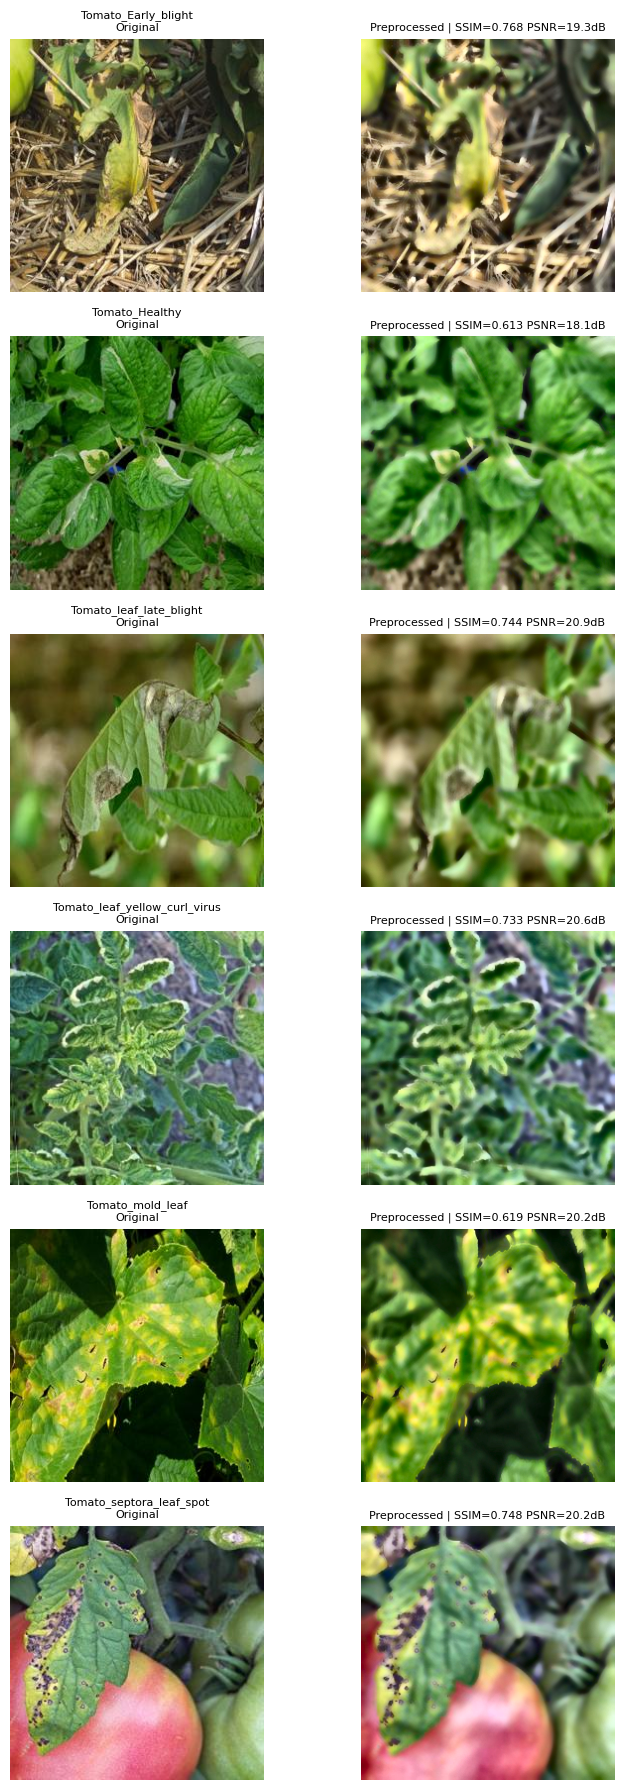

In [2]:
from skimage.metrics import structural_similarity as ssim, peak_signal_noise_ratio as psnr

def preprocess(img_bgr):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l_bilateral = cv2.bilateralFilter(l, d=9, sigmaColor=75, sigmaSpace=75)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_clahe = clahe.apply(l_bilateral)
    lab_processed = cv2.merge([l_clahe, a, b])
    return cv2.cvtColor(lab_processed, cv2.COLOR_LAB2BGR)

fig, axes = plt.subplots(len(classes), 2, figsize=(8, 3 * len(classes)))

print(f"{'Class':<35} {'SSIM':>6}  {'PSNR (dB)':>10}")
print("-" * 55)

for i, cls in enumerate(classes):
    cls_path = os.path.join(data_dir, cls)
    img_bgr = cv2.imread(os.path.join(cls_path, get_images(cls_path)[0]))
    img_proc = preprocess(img_bgr)

    orig_rgb = cv2.cvtColor(img_bgr,  cv2.COLOR_BGR2RGB)
    proc_rgb = cv2.cvtColor(img_proc, cv2.COLOR_BGR2RGB)

    ssim_val = ssim(orig_rgb, proc_rgb, channel_axis=2, data_range=255)
    psnr_val = psnr(orig_rgb, proc_rgb, data_range=255)
    print(f"{cls:<35} {ssim_val:>6.4f}  {psnr_val:>10.2f}")

    axes[i][0].imshow(orig_rgb)
    axes[i][0].set_title(f"{cls}\nOriginal", fontsize=8)
    axes[i][0].axis('off')
    axes[i][1].imshow(proc_rgb)
    axes[i][1].set_title(f"Preprocessed | SSIM={ssim_val:.3f} PSNR={psnr_val:.1f}dB", fontsize=8)
    axes[i][1].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "part2_preprocessing.png"), dpi=100)
plt.show()

# **Part 3 — Training**

### 3.1 — Imports and configuration

Importing the required libraries and defining the hyperparameters:
- **IMG_SIZE = 128**: input image size
- **BATCH_SIZE = 32**: number of images per batch
- **SEED = 42**: fixed random seed (data split and weight initialization) so that runs are comparable
- Collecting all image paths and their corresponding labels

In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

SEED = 42
tf.keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow

IMG_SIZE   = 128
BATCH_SIZE = 32
EPOCHS     = 40
NUM_CLASSES = len(classes)
class_to_idx = {cls: i for i, cls in enumerate(classes)}

# --- Collecting image paths ---
all_paths, all_labels = [], []
for cls in classes:
    cls_path = os.path.join(data_dir, cls)
    for img_name in get_images(cls_path):
        all_paths.append(os.path.join(cls_path, img_name))
        all_labels.append(cls)

### 3.2 — Dataset split + image loading

Splitting the dataset into three stratified sets:
- **70%** Training
- **20%** Validation
- **10%** Test

Then loading the images with the `make_dataset` function, which:
1. Reads each image
2. Applies preprocessing (optional)
3. Resizes to **128×128**
4. Normalizes pixel values to **[0, 1]**

The split is done on file paths, so the **same images** end up in the same sets for both experiments (with and without preprocessing).

In [4]:
X_train, X_temp, y_train, y_temp = train_test_split(all_paths, all_labels, test_size=0.30, random_state=SEED, stratify=all_labels)
X_val,   X_test, y_val,   y_test = train_test_split(X_temp,   y_temp,      test_size=1/3,  random_state=SEED, stratify=y_temp)
print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

def make_dataset(paths, labels, apply_preprocessing=True):
    imgs, labs = [], []
    for p, l in zip(paths, labels):
        img_bgr = cv2.imread(p)
        if apply_preprocessing:
            img_bgr = preprocess(img_bgr)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE)).astype(np.float32) / 255.0
        imgs.append(img)
        labs.append(tf.keras.utils.to_categorical(class_to_idx[l], NUM_CLASSES))
    return np.array(imgs), np.array(labs)

print("Loading train...") ; X_tr, y_tr = make_dataset(X_train, y_train)
print("Loading val...")   ; X_v,  y_v  = make_dataset(X_val,   y_val)
print("Loading test...")  ; X_te, y_te = make_dataset(X_test,  y_test)
print("Loading complete!")

Train: 5040 | Val: 1440 | Test: 720
Loading train...
Loading val...
Loading test...
Loading complete!


### 3.3 — CNN architecture

Convolutional neural network made of:
- **3 blocks** Conv2D → BatchNormalization → MaxPooling2D → Dropout (32, 64 and 128 filters)
- **1 Dense block**: Flatten → Dense(256) → BatchNormalization → Dropout
- **Output layer**: Dense(6, softmax) for the 6 classes

Justified choices:
- **Conv2D with 3×3 kernels**: learn local patterns (spots, edges, textures); the number of filters grows (32 → 64 → 128) so deeper layers capture more complex patterns
- **BatchNormalization**: stabilizes and speeds up training
- **MaxPooling**: progressively reduces the spatial dimensions and the number of parameters
- **Dropout** (0.25 → 0.5): reduces overfitting; the strongest rate is placed on the large Dense layer
- **Softmax + categorical cross-entropy**: multi-class classification with one-hot labels
- **Adam**: adaptive learning rate, a robust default optimizer

In [5]:
def build_cnn():
    model = models.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

        layers.Conv2D(32,  (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),
        layers.Dropout(0.25),

        layers.Conv2D(64,  (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

tf.keras.utils.set_random_seed(SEED)
model = build_cnn()
model.summary()

I0000 00:00:1793543763.167456      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793543763.171172      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,485,574 (32.37 MB)

 Trainable params: 8,484,614 (32.37 MB)

 Non-trainable params: 960 (3.75 KB)

### 3.4 — Training + loss and accuracy curves

Training with the following callbacks:
- **EarlyStopping**: stops if `val_loss` does not improve for 10 epochs, and restores the best weights
- **ReduceLROnPlateau**: halves the learning rate if `val_loss` stagnates for 4 epochs

Both callbacks monitor `val_loss`, which is smoother than `val_accuracy` early in training (BatchNormalization statistics need a few epochs to settle, and a validation accuracy stuck near chance level could otherwise trigger an early stop on a poor model).

Training the model WITH preprocessing...
Epoch 1/40
  5/158 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.2589 - loss: 2.6960

I0000 00:00:1793543777.635413      74 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


158/158 ━━━━━━━━━━━━━━━━━━━━ 22s 72ms/step - accuracy: 0.5708 - loss: 1.2584 - val_accuracy: 0.1667 - val_loss: 32.5587 - learning_rate: 0.0010
Epoch 2/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.7502 - loss: 0.7159 - val_accuracy: 0.2562 - val_loss: 2.5050 - learning_rate: 0.0010
Epoch 3/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.8367 - loss: 0.4789 - val_accuracy: 0.4868 - val_loss: 1.8292 - learning_rate: 0.0010
Epoch 4/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.8835 - loss: 0.3443 - val_accuracy: 0.7160 - val_loss: 0.9008 - learning_rate: 0.0010
Epoch 5/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9129 - loss: 0.2647 - val_accuracy: 0.7618 - val_loss: 0.8218 - learning_rate: 0.0010
Epoch 6/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9427 - loss: 0.1750 - val_accuracy: 0.7944 - val_loss: 0.7142 - learning_rate: 0.0010
Epoch 7/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9657 - loss: 0.1267 - va

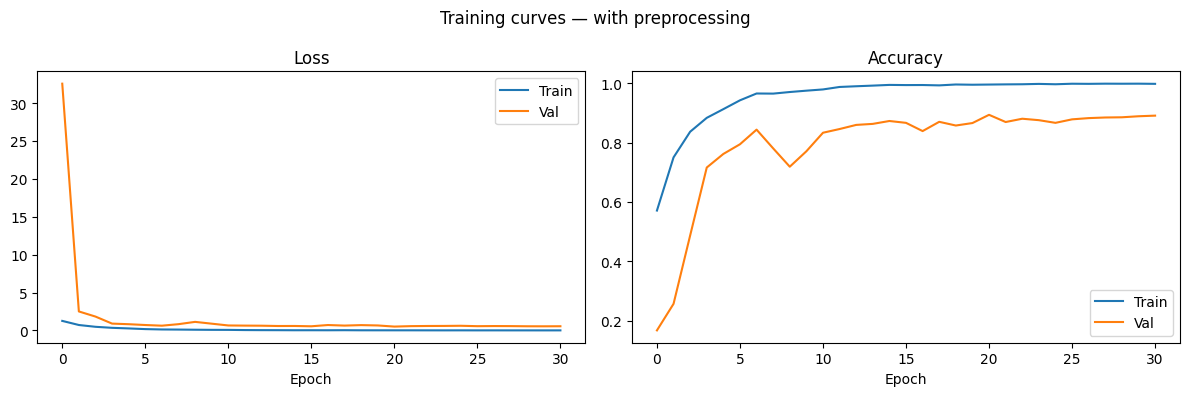

In [6]:
def get_callbacks():
    # New callback objects for each training run (they keep internal state)
    return [
        EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6, verbose=1)
    ]

# TRAINING
print("Training the model WITH preprocessing...")
history = model.fit(
    X_tr, y_tr,
    validation_data=(X_v, y_v),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks(),
    verbose=1
)

# SAVING (modern format)
model_path = os.path.join(OUTPUT_DIR, "model_with_preprocessing.keras")
model.save(model_path)
print(f"Model saved successfully → {model_path}")

# CURVES
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'], label='Train')
axes[0].plot(history.history['val_loss'], label='Val')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Train')
axes[1].plot(history.history['val_accuracy'], label='Val')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.suptitle("Training curves — with preprocessing")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "part3_curves.png"), dpi=150)
plt.show()

### 3.5 — Test-set evaluation + confusion matrix + classification report (precision, recall, F1-score per class)

Evaluating the model on the test set:
- Classification report (precision, recall, F1-score per class)
- Confusion matrix

The `evaluate_model` function is reused for the second experiment (without preprocessing).

Classification report — with preprocessing
                               precision    recall  f1-score   support

          Tomato_Early_blight       0.88      0.89      0.88       120
               Tomato_Healthy       0.90      0.94      0.92       120
      Tomato_leaf_late_blight       0.81      0.88      0.84       120
Tomato_leaf_yellow_curl_virus       0.88      0.99      0.93       120
             Tomato_mold_leaf       0.91      0.80      0.85       120
     Tomato_septora_leaf_spot       0.87      0.75      0.81       120

                     accuracy                           0.88       720
                    macro avg       0.88      0.88      0.87       720
                 weighted avg       0.88      0.88      0.87       720



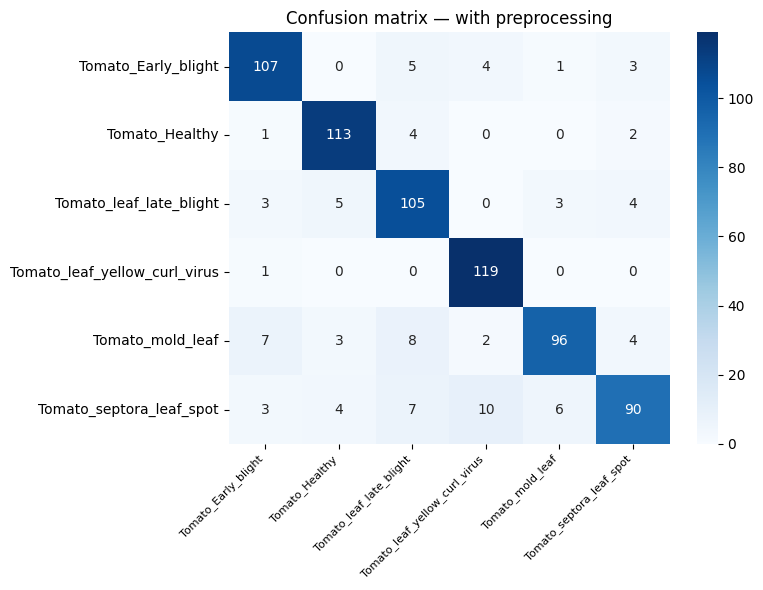

In [7]:
def evaluate_model(model, X, y, title, cmap, filename):
    """Print the classification report, plot the confusion matrix and return summary metrics."""
    y_pred = np.argmax(model.predict(X, verbose=0), axis=1)
    y_true = np.argmax(y, axis=1)

    print(f"Classification report — {title}")
    print(classification_report(y_true, y_pred, target_names=classes, zero_division=0))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap=cmap)
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.title(f"Confusion matrix — {title}")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=120)
    plt.show()

    report = classification_report(y_true, y_pred, target_names=classes, zero_division=0, output_dict=True)
    return {
        "test_acc": report["accuracy"],
        "macro_f1": report["macro avg"]["f1-score"],
        "f1_per_class": {c: report[c]["f1-score"] for c in classes},
    }

res_with = evaluate_model(model, X_te, y_te, "with preprocessing", "Blues", "part3_confusion_with.png")
res_with["val_acc"] = model.evaluate(X_v, y_v, verbose=0)[1]

### 3.6 — Training WITHOUT preprocessing + comparison

Training the same CNN with the **same hyperparameters**, the same seed and the same train/validation/test split, but on the **original images without preprocessing**, to compare performance.

Training the model WITHOUT preprocessing...
Epoch 1/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 17s 64ms/step - accuracy: 0.5387 - loss: 1.4050 - val_accuracy: 0.1667 - val_loss: 18.3162 - learning_rate: 0.0010
Epoch 2/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.6522 - loss: 1.0192 - val_accuracy: 0.1785 - val_loss: 3.9881 - learning_rate: 0.0010
Epoch 3/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.7569 - loss: 0.7035 - val_accuracy: 0.3347 - val_loss: 3.1276 - learning_rate: 0.0010
Epoch 4/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.8252 - loss: 0.5272 - val_accuracy: 0.6924 - val_loss: 0.9466 - learning_rate: 0.0010
Epoch 5/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.8810 - loss: 0.3484 - val_accuracy: 0.6687 - val_loss: 1.0876 - learning_rate: 0.0010
Epoch 6/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.9073 - loss: 0.2868 - val_accuracy: 0.7840 - val_loss: 0.6525 - learning_rate: 0.0010
Epoch 7/40
158/158 ━━━━━━━━━━━━━━━━━

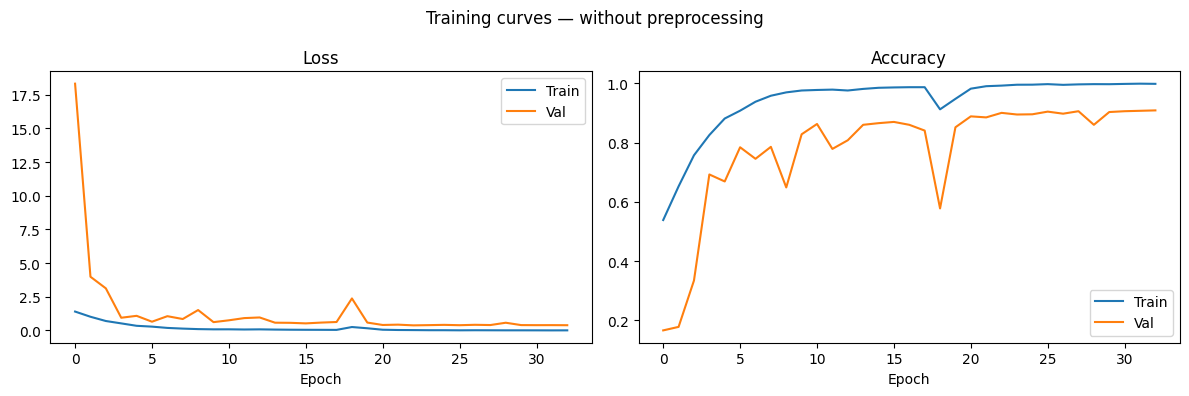

Classification report — without preprocessing
                               precision    recall  f1-score   support

          Tomato_Early_blight       0.85      0.91      0.88       120
               Tomato_Healthy       0.97      0.93      0.95       120
      Tomato_leaf_late_blight       0.86      0.87      0.86       120
Tomato_leaf_yellow_curl_virus       0.94      0.97      0.96       120
             Tomato_mold_leaf       0.92      0.82      0.87       120
     Tomato_septora_leaf_spot       0.80      0.81      0.80       120

                     accuracy                           0.89       720
                    macro avg       0.89      0.89      0.89       720
                 weighted avg       0.89      0.89      0.89       720



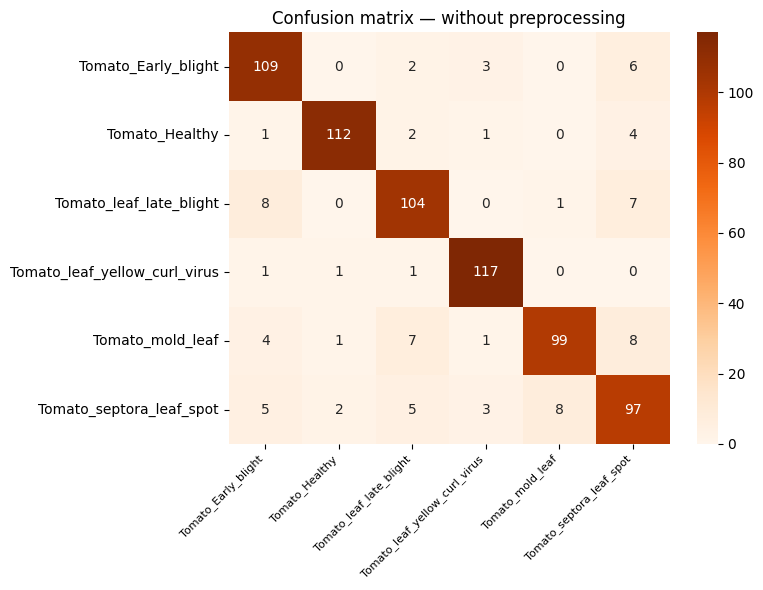

In [8]:
# TRAINING WITHOUT PREPROCESSING
print("Training the model WITHOUT preprocessing...")

X_tr2, y_tr2 = make_dataset(X_train, y_train, apply_preprocessing=False)
X_v2,  y_v2  = make_dataset(X_val,   y_val,   apply_preprocessing=False)
X_te2, y_te2 = make_dataset(X_test,  y_test,  apply_preprocessing=False)

tf.keras.utils.set_random_seed(SEED)   # same weight initialization as the first model
model2 = build_cnn()

history2 = model2.fit(
    X_tr2, y_tr2,
    validation_data=(X_v2, y_v2),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks(),
    verbose=1
)

# SAVING (modern format)
model2_path = os.path.join(OUTPUT_DIR, "model_without_preprocessing.keras")
model2.save(model2_path)
print(f"Model WITHOUT preprocessing saved → {model2_path}")

# Training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history2.history['loss'], label='Train')
axes[0].plot(history2.history['val_loss'], label='Val')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history2.history['accuracy'], label='Train')
axes[1].plot(history2.history['val_accuracy'], label='Val')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.suptitle("Training curves — without preprocessing")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "part3_curves_without.png"), dpi=150)
plt.show()

# EVALUATION
res_without = evaluate_model(model2, X_te2, y_te2, "without preprocessing", "Oranges", "part3_confusion_without.png")
res_without["val_acc"] = model2.evaluate(X_v2, y_v2, verbose=0)[1]

### 3.7 — Final comparison

Comparing the two models on the **same test set**:
- Model **with** preprocessing (LAB + Bilateral + CLAHE)
- Model **without** preprocessing

The comparison is based on the test set (images never used for training or for early stopping), plus the per-class F1-scores.

In [9]:
# FINAL COMPARISON
print(f"{'Model':<28} {'Val acc':>8} {'Test acc':>9} {'Macro F1':>9}")
print("-" * 57)
for name, r in [("WITH preprocessing", res_with), ("WITHOUT preprocessing", res_without)]:
    print(f"{name:<28} {r['val_acc']:>8.4f} {r['test_acc']:>9.4f} {r['macro_f1']:>9.4f}")

print(f"\n{'F1-score per class':<35} {'With':>7} {'Without':>8} {'Diff':>7}")
print("-" * 60)
for c in classes:
    fw, fo = res_with["f1_per_class"][c], res_without["f1_per_class"][c]
    print(f"{c:<35} {fw:>7.3f} {fo:>8.3f} {fw - fo:>+7.3f}")

# Sanity check: with 6 balanced classes, random guessing gives about 1/6 = 17% accuracy
chance = 1 / NUM_CLASSES
failed = False
for name, r in [("WITH", res_with), ("WITHOUT", res_without)]:
    if r["test_acc"] < 0.5:
        failed = True
        print(f"\n⚠ The model {name} preprocessing reaches only {r['test_acc']:.1%} test accuracy "
              f"(chance level ≈ {chance:.1%}): training probably failed. Check its training curves and re-run the training cell.")

# Conclusion (generated from the results above)
diff = res_with["test_acc"] - res_without["test_acc"]
print(f"\nTest accuracy difference (with − without preprocessing): {diff:+.4f}")
if failed:
    print("No conclusion can be drawn from this run, because at least one model did not train properly.")
elif abs(diff) < 0.02:
    print("The two models perform similarly: a difference of less than about 2 points on a 720-image test set "
          "can easily come from chance (random initialization, training randomness), "
          "so this run gives no clear evidence that the preprocessing helps or hurts.")
elif diff > 0:
    print("Preprocessing (LAB + Bilateral + CLAHE) improved the test accuracy in this run.")
else:
    print("Preprocessing (LAB + Bilateral + CLAHE) lowered the test accuracy in this run.")
print("Note: this is a single training run per model; repeating it with several seeds would give a more reliable comparison.")

Model                         Val acc  Test acc  Macro F1
---------------------------------------------------------
WITH preprocessing             0.8938    0.8750    0.8734
WITHOUT preprocessing          0.9000    0.8861    0.8861

F1-score per class                     With  Without    Diff
------------------------------------------------------------
Tomato_Early_blight                   0.884    0.879  +0.005
Tomato_Healthy                        0.922    0.949  -0.027
Tomato_leaf_late_blight               0.843    0.863  -0.020
Tomato_leaf_yellow_curl_virus         0.933    0.955  -0.022
Tomato_mold_leaf                      0.850    0.868  -0.019
Tomato_septora_leaf_spot              0.807    0.802  +0.006

Test accuracy difference (with − without preprocessing): -0.0111
The two models perform similarly: a difference of less than about 2 points on a 720-image test set can easily come from chance (random initialization, training randomness), so this run gives no clear evidence that